<a href="https://colab.research.google.com/github/HC-AIGroup/CS5330_F26/blob/main/MODULE%207/Lucas_Kanade.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

corners found: 39
moving corners: 16  still corners: 23
car motion vector (u, v) = [6. 0.] pixels per frame


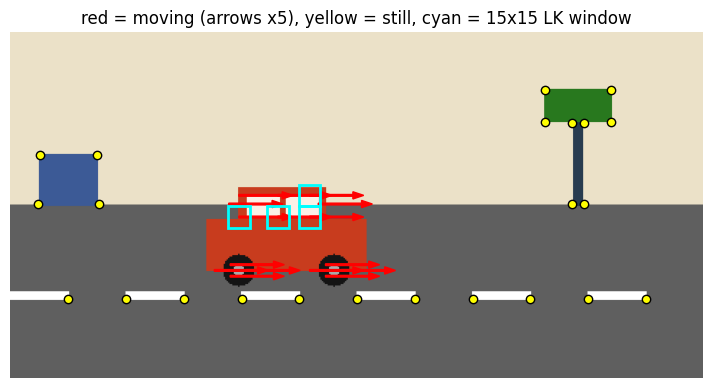

speed = 6.0 px/frame x 30 fps = 180 px/s = 27 km/h


In [1]:
import cv2, numpy as np
import matplotlib.pyplot as plt

# ---------- Step 1: make a simple video of a red car (6 px/frame to the right) ----------
W, H, SPEED = 480, 240, 6
def make_frame(t):
    im = np.full((H, W, 3), (200, 225, 235), np.uint8)                   # sky
    cv2.rectangle(im, (0, 120), (W, H), (95, 95, 95), -1)               # road
    for x in range(0, W, 80):                                           # lane dashes
        cv2.rectangle(im, (x, 180), (x + 40, 185), (255, 255, 255), -1)
    cv2.rectangle(im, (20, 85), (60, 120), (150, 90, 60), -1)           # house
    cv2.rectangle(im, (390, 60), (396, 120), (80, 60, 40), -1)          # sign pole
    cv2.rectangle(im, (370, 40), (416, 62), (30, 120, 40), -1)          # sign
    x, y = 130 + SPEED * t, 130                                         # the car moves
    cv2.rectangle(im, (x, y), (x + 110, y + 35), (30, 60, 200), -1)     # body (red in BGR)
    cv2.rectangle(im, (x + 22, y - 22), (x + 82, y), (30, 60, 200), -1) # roof
    cv2.rectangle(im, (x + 28, y - 17), (x + 50, y - 2), (230, 240, 250), -1)  # windows
    cv2.rectangle(im, (x + 55, y - 17), (x + 77, y - 2), (230, 240, 250), -1)
    for wx in (x + 22, x + 88):                                         # wheels
        cv2.circle(im, (wx, y + 35), 11, (20, 20, 20), -1)
        cv2.circle(im, (wx, y + 35), 4, (170, 170, 170), -1)
    return im

frame1, frame2 = make_frame(0), make_frame(1)
gray1 = cv2.cvtColor(frame1, cv2.COLOR_BGR2GRAY)
gray2 = cv2.cvtColor(frame2, cv2.COLOR_BGR2GRAY)

# ---------- Step 2: find good corners in frame 1 (Shi-Tomasi) ----------
p1 = cv2.goodFeaturesToTrack(gray1,
        maxCorners=60,      # keep at most 60 corners
        qualityLevel=0.05,  # keep corners with score >= 5% of the best corner
        minDistance=8,      # corners at least 8 px apart
        blockSize=3)        # Shi-Tomasi window: 3x3 around each pixel
print("corners found:", len(p1))

# ---------- Step 3: Lucas-Kanade -> where did each corner go in frame 2? ----------
WIN = 15                                       # LK window: 15x15 around each corner
p2, status, err = cv2.calcOpticalFlowPyrLK(gray1, gray2, p1, None,
                                           winSize=(WIN, WIN),  # same motion assumed inside
                                           maxLevel=2)          # pyramid: 3 levels
ok = status.ravel() == 1                       # 1 = found, 0 = lost
old = p1[ok].reshape(-1, 2)
new = p2[ok].reshape(-1, 2)

# ---------- Step 4: motion vector (u, v) for every corner ----------
motion = new - old                             # u = right/left, v = down/up
speed = np.linalg.norm(motion, axis=1)         # length of each arrow

# ---------- Step 5: detect motion: moving vs still ----------
moving = speed > 1.0                           # more than 1 pixel = moving
print("moving corners:", moving.sum(), " still corners:", (~moving).sum())
print("car motion vector (u, v) =", motion[moving].mean(axis=0).round(2), "pixels per frame")

# ---------- Step 6: draw the result ----------
out = cv2.cvtColor(frame2, cv2.COLOR_BGR2RGB)
plt.figure(figsize=(9, 4.5))
plt.imshow(out)
for (x0, y0), (u, v), m in zip(old, motion, moving):
    if m:   # moving: red arrow (drawn 5x longer so it's visible)
        plt.arrow(x0, y0, 5 * u, 5 * v, color="red", width=1.2, head_width=5)
    else:   # still: yellow dot
        plt.plot(x0, y0, "o", color="yellow", markeredgecolor="black")
for (x0, y0) in old[moving][:4]:               # show the 15x15 LK window on 4 car corners
    plt.gca().add_patch(plt.Rectangle((x0 - WIN/2, y0 - WIN/2), WIN, WIN,
                                      fill=False, edgecolor="cyan", lw=2))
plt.title("red = moving (arrows x5), yellow = still, cyan = 15x15 LK window")
plt.axis("off")
plt.show()

# ---------- Step 7 (optional): speed in km/h ----------
FPS = 30                                       # frames per second of the video
PX_PER_M = 110 / 4.5                           # car is 110 px long, a real car is ~4.5 m
u = motion[moving].mean(axis=0)[0]
print(f"speed = {u:.1f} px/frame x {FPS} fps = {u*FPS:.0f} px/s = {u*FPS/PX_PER_M*3.6:.0f} km/h")

Later if you want your own video, replace step 1 with below code:
from google.colab import files
up = files.upload()                       # choose your video file
cap = cv2.VideoCapture(list(up.keys())[0])
ok, frame1 = cap.read()
ok, frame2 = cap.read()                   # the next frame